Magnitud         Teorico  Modelo ideal
f0 [Hz]          5032.92       5032.92
Imax [mA]          10.00         10.00
f1 [Hz]          4299.67       4299.67
f2 [Hz]          5891.22       5891.22
Df [Hz]          1591.55       1591.55
Q                   3.16          3.16


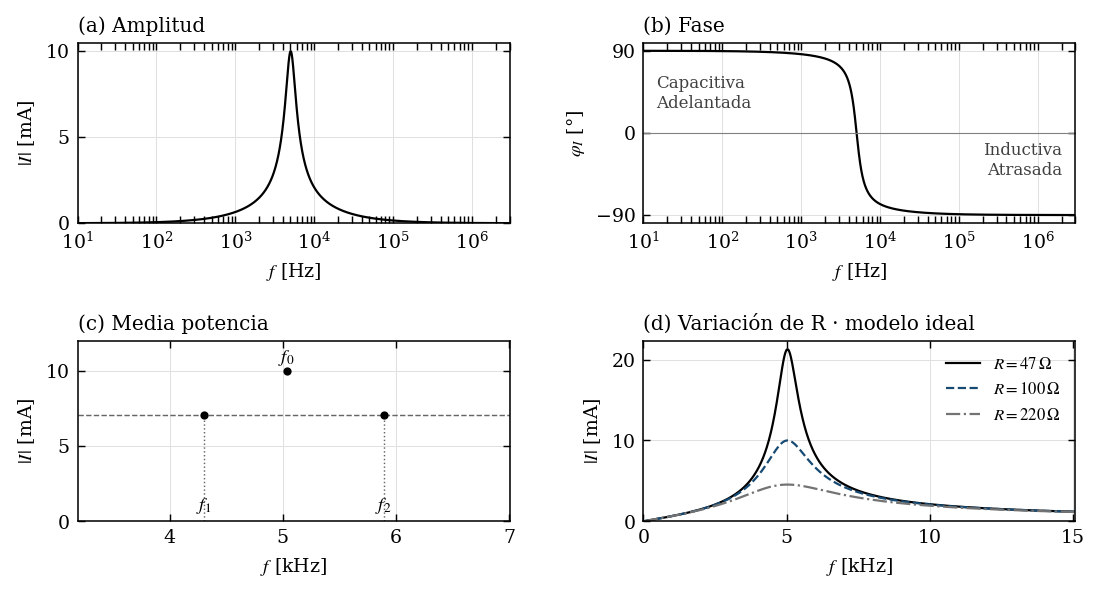

In [3]:

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D

# ------------------------------------------------------------------
# 1. Configuracion del circuito y de la figura
# ------------------------------------------------------------------
R, L, C, VIN = 100.0, 10e-3, 100e-9, 1.0   # ohm, H, F, V
F_MIN, F_MAX = 10.0, 3e6                   # Hz (barrido ampliado para ver la campana completa)

# Ruta al .txt exportado de LTspice (freq + I(...) complejo). None = solo modelo ideal.
ARCHIVO = None

RESISTENCIAS_COMPARACION = (47.0, 100.0, 220.0)  # Actividad 1, punto 7

AZUL = "#174a73"
ANCHO_CM, ALTO_CM = 17.8, 10.0

ESTILO = {
    "font.family": "DejaVu Serif",
    "mathtext.fontset": "stix",
    "font.size": 8.5,
    "axes.labelsize": 8.5,
    "axes.titlesize": 9,
    "axes.linewidth": 0.7,
    "axes.edgecolor": "black",
    "legend.frameon": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "figure.dpi": 160,
}


# ------------------------------------------------------------------
# 2. Modelo analitico
# ------------------------------------------------------------------
def corriente_teorica(f, resistencia):
    """Corriente compleja del RLC serie (A)."""
    omega = 2 * np.pi * np.asarray(f)
    Z = resistencia + 1j * (omega * L - 1 / (omega * C))
    return VIN / Z


def valores_teoricos(resistencia):
    """f0, Imax, f1, f2, ancho de banda y Q, en forma cerrada."""
    raiz = np.sqrt(resistencia ** 2 + 4 * L / C)
    f0 = 1 / (2 * np.pi * np.sqrt(L * C))
    f1 = (raiz - resistencia) / (4 * np.pi * L)
    f2 = (raiz + resistencia) / (4 * np.pi * L)
    bw = resistencia / (2 * np.pi * L)
    return {"f0": f0, "Imax": VIN / resistencia, "f1": f1, "f2": f2, "BW": bw, "Q": f0 / bw}


# ------------------------------------------------------------------
# 3. Lectura del archivo exportado por LTspice
# ------------------------------------------------------------------
def leer_ltspice(ruta):
    """
    Lee frecuencia + una corriente I(...) exportada como par complejo.
    Admite pares "(magnitud,fase_deg)" y "(magnitud_dB,fase_deg)".
    Exportar un unico paso de .step por archivo.
    """
    texto = Path(ruta).expanduser().read_text(encoding="utf-8-sig", errors="replace")
    lineas = [linea for linea in texto.splitlines() if linea.strip()]

    sep = "\t" if "\t" in lineas[0] else ","
    filas = [linea.split(sep) for linea in lineas[1:]]

    def leer_par(celda):
        a, b = celda.strip().strip("()").split(",")
        b = b.lower().replace("°", "").replace("deg", "")
        magnitud, fase = float(a), float(b)
        if "db" in a.lower():
            magnitud = 10 ** (float(a.lower().replace("db", "")) / 20)
        return magnitud * np.exp(1j * np.deg2rad(fase))

    frecuencias = np.array([float(fila[0]) for fila in filas])
    corriente = np.array([leer_par(fila[1]) for fila in filas])
    return frecuencias, corriente


# ------------------------------------------------------------------
# 4. Analisis de los datos: pico y cortes a -3 dB
# ------------------------------------------------------------------
def analizar(f, corriente):
    """Determina f0, Imax y los cortes a -3 dB (interpolando en log10 f)."""
    orden = np.argsort(f)
    f, corriente = f[orden], corriente[orden]
    amplitud = np.abs(corriente)

    i_pico = int(np.argmax(amplitud))
    nivel = amplitud[i_pico] / np.sqrt(2)

    def interpolar_cruce(i):
        a, b = amplitud[i], amplitud[i + 1]
        t = (nivel - a) / (b - a)
        return 10 ** (np.log10(f[i]) + t * np.log10(f[i + 1] / f[i]))

    cambios = np.flatnonzero((amplitud[:-1] - nivel) * (amplitud[1:] - nivel) <= 0)
    f1 = interpolar_cruce(cambios[cambios < i_pico][-1])
    f2 = interpolar_cruce(cambios[cambios >= i_pico][0])

    fase = np.rad2deg(np.unwrap(np.angle(corriente)))
    f0 = float(f[i_pico])

    resultados = {
        "f0": f0, "Imax": float(amplitud[i_pico]),
        "f1": f1, "f2": f2, "BW": f2 - f1, "Q": f0 / (f2 - f1),
    }
    return f, amplitud, fase, resultados


# ------------------------------------------------------------------
# 5. Figura de 4 paneles (igual a la Figura 2 del informe)
# ------------------------------------------------------------------
def eje_log(ax):
    ax.set_xscale("log")
    ax.tick_params(which="both", direction="in", top=True, right=True, length=3, width=0.65)
    ax.grid(which="major", color="0.88", linewidth=0.45)
    ax.set_axisbelow(True)


def graficar(f, amplitud, fase, resultados, usar_datos):
    f_modelo = np.geomspace(F_MIN, F_MAX, 4000)
    i_modelo = corriente_teorica(f_modelo, R)

    with plt.rc_context(ESTILO):
        fig, ((a, b), (c, d)) = plt.subplots(2, 2, figsize=(ANCHO_CM / 2.54, ALTO_CM / 2.54))
        fig.subplots_adjust(left=0.09, right=0.98, bottom=0.11, top=0.87, wspace=0.31, hspace=0.65)

        # --- (a) Amplitud en todo el barrido -----------------------------
        if usar_datos:
            a.plot(f, amplitud * 1e3, "o-", color=AZUL, ms=2.2, mfc="white", mew=0.55,
                   lw=0.9, markevery=max(1, len(f) // 55), label="LTspice")
            a.plot(f_modelo, np.abs(i_modelo) * 1e3, "k--", lw=0.85, label="Modelo ideal")
        else:
            a.plot(f_modelo, np.abs(i_modelo) * 1e3, "k-", lw=1.0, label="Modelo ideal")
        a.set_title("(a) Amplitud", loc="left", pad=5)
        a.set_ylabel(r"$|I|$ [mA]"); a.set_xlabel(r"$f$ [Hz]")
        eje_log(a); a.set_xlim(F_MIN, F_MAX); a.set_ylim(bottom=0)

        # --- (b) Fase ------------------------------------------------------
        fase_modelo = np.rad2deg(np.unwrap(np.angle(i_modelo)))
        if usar_datos:
            b.plot(f, fase, color=AZUL, lw=0.95)
            b.plot(f_modelo, fase_modelo, "k--", lw=0.85)
        else:
            b.plot(f_modelo, fase_modelo, "k-", lw=1.0)
        b.axhline(0, color="0.5", lw=0.5)
        b.text(0.03, 0.64, "Capacitiva\nAdelantada", transform=b.transAxes, fontsize=7.5, color="0.25")
        b.text(0.97, 0.27, "Inductiva\nAtrasada", transform=b.transAxes, fontsize=7.5,
               ha="right", color="0.25")
        b.set_title("(b) Fase", loc="left", pad=5)
        b.set_ylabel(r"$\varphi_I$ [°]"); b.set_xlabel(r"$f$ [Hz]")
        eje_log(b); b.set_xlim(F_MIN, F_MAX); b.set_yticks([-90, 0, 90])

        # --- (c) Detalle a media potencia -----------------------------------
        f0, f1, f2 = resultados["f0"] / 1e3, resultados["f1"] / 1e3, resultados["f2"] / 1e3
        pico, nivel = resultados["Imax"] * 1e3, resultados["Imax"] * 1e3 / np.sqrt(2)
        c.axhline(nivel, color="0.4", ls="--", lw=0.65)
        c.vlines([f1, f2], 0, nivel, color="0.4", ls=":", lw=0.65)
        c.plot([f1, f2, f0], [nivel, nivel, pico], "ko", ms=2.7)
        c.annotate(r"$f_0$", (f0, pico), xytext=(0, 4), textcoords="offset points", ha="center")
        for x, etiqueta in ((f1, r"$f_1$"), (f2, r"$f_2$")):
            c.text(x, 0.03, etiqueta, transform=c.get_xaxis_transform(), ha="center", va="bottom")
        c.set_title("(c) Media potencia", loc="left", pad=5)
        c.set_ylabel(r"$|I|$ [mA]"); c.set_xlabel(r"$f$ [kHz]")
        c.tick_params(direction="in", top=True, right=True, length=3, width=0.65)
        c.grid(color="0.88", linewidth=0.45); c.set_axisbelow(True)
        ancho = f2 - f1
        c.set_xlim(f1 - 0.7 * ancho, f2 + 0.7 * ancho); c.set_ylim(0, pico * 1.2)

        # --- (d) Variacion con R (modelo ideal) -----------------------------
        for resistencia, color, trazo in zip(RESISTENCIAS_COMPARACION, ("black", AZUL, "0.45"), ("-", "--", "-.")):
            d.plot(f_modelo / 1e3, np.abs(corriente_teorica(f_modelo, resistencia)) * 1e3,
                   color=color, ls=trazo, lw=1.0, label=rf"$R={resistencia:g}\,\Omega$")
        d.set_title("(d) Variación de R · modelo ideal", loc="left", pad=5)
        d.set_ylabel(r"$|I|$ [mA]"); d.set_xlabel(r"$f$ [kHz]")
        d.tick_params(direction="in", top=True, right=True, length=3, width=0.65)
        d.grid(color="0.88", linewidth=0.45); d.set_axisbelow(True)
        d.set_xlim(0, min(F_MAX / 1e3, 3 * resultados["f0"] / 1e3)); d.set_ylim(bottom=0)
        d.legend(loc="upper right", fontsize=7.5)

        if usar_datos:
            fig.legend(handles=[
                Line2D([], [], color=AZUL, marker="o", ms=2.7, mfc="white", mew=0.55, lw=0.9, label="LTspice"),
                Line2D([], [], color="black", ls="--", lw=0.85, label="Modelo ideal"),
            ], loc="upper center", ncol=2, fontsize=8, bbox_to_anchor=(0.5, 0.995))

    return fig


# ------------------------------------------------------------------
# 6. Tabla 1: teorico vs. LTspice
# ------------------------------------------------------------------
def imprimir_tabla(teorico, medido, usar_datos):
    etiqueta = "LTspice" if usar_datos else "Modelo ideal"
    filas = [
        ("f0 [Hz]", teorico["f0"], medido["f0"]),
        ("Imax [mA]", teorico["Imax"] * 1e3, medido["Imax"] * 1e3),
        ("f1 [Hz]", teorico["f1"], medido["f1"]),
        ("f2 [Hz]", teorico["f2"], medido["f2"]),
        ("Df [Hz]", teorico["BW"], medido["BW"]),
        ("Q", teorico["Q"], medido["Q"]),
    ]
    print(f"{'Magnitud':<12}{'Teorico':>12}{etiqueta:>14}")
    for nombre, t, m in filas:
        print(f"{nombre:<12}{t:>12.2f}{m:>14.2f}")


# ------------------------------------------------------------------
# 7. Ejecucion
# ------------------------------------------------------------------
def ejecutar():
    teorico = valores_teoricos(R)
    usar_datos = ARCHIVO is not None

    if usar_datos:
        f, corriente = leer_ltspice(ARCHIVO)
    else:
        f = np.geomspace(F_MIN, F_MAX, 4000)
        corriente = corriente_teorica(f, R)

    f, amplitud, fase, resultados = analizar(f, corriente)
    if not usar_datos:
        resultados = teorico  # el "modelo ideal" coincide exactamente con la formula cerrada

    fig = graficar(f, amplitud, fase, resultados, usar_datos)
    fig.savefig("RLC_resonancia.png", dpi=600, bbox_inches="tight", facecolor="white")

    imprimir_tabla(teorico, resultados, usar_datos)
    plt.show()
    return fig, resultados


if __name__ == "__main__":
    ejecutar()

            PB teorico  PB LTspice  PA teorico  PA LTspice
fc [Hz]        1591.55           -     1591.55           -


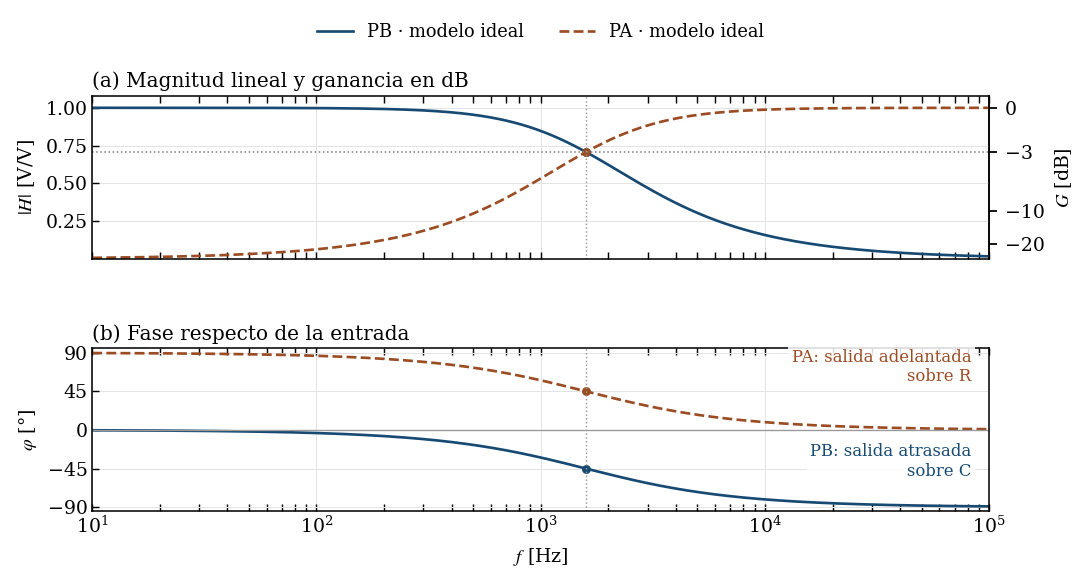

In [4]:


from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# ------------------------------------------------------------------
# 1. Configuracion
# ------------------------------------------------------------------
R, C, VIN = 1000.0, 100e-9, 1.0    # ohm, F, V
F_MIN, F_MAX = 10.0, 100_000.0     # Hz

# Rutas a los .txt exportados de LTspice (freq + V(out)/V(in) complejo).
# None = mostrar solo el modelo ideal.
ARCHIVO_PB = None
ARCHIVO_PA = None

AZUL, NARANJA = "#174a73", "#9b4c23"
ANCHO_CM, ALTO_CM = 17.8, 8.8

ESTILO = {
    "font.family": "DejaVu Serif",
    "mathtext.fontset": "stix",
    "font.size": 8.5,
    "axes.labelsize": 8.5,
    "axes.titlesize": 9,
    "axes.linewidth": 0.7,
    "axes.edgecolor": "black",
    "legend.frameon": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "figure.dpi": 160,
}


# ------------------------------------------------------------------
# 2. Modelo analitico
# ------------------------------------------------------------------
def transferencia(f, tipo):
    """H(jw) ideal, sin carga adicional. tipo: 'PB' o 'PA'."""
    x = 2 * np.pi * np.asarray(f) * R * C
    return 1 / (1 + 1j * x) if tipo == "PB" else (1j * x) / (1 + 1j * x)


def fc_teorica():
    return 1 / (2 * np.pi * R * C)


# ------------------------------------------------------------------
# 3. Lectura del archivo exportado por LTspice
# ------------------------------------------------------------------
def leer_transferencia(ruta):
    """Lee frecuencia + V(out)/V(in) exportada como par complejo."""
    texto = Path(ruta).expanduser().read_text(encoding="utf-8-sig", errors="replace")
    lineas = [linea for linea in texto.splitlines() if linea.strip()]

    sep = "\t" if "\t" in lineas[0] else ","
    filas = [linea.split(sep) for linea in lineas[1:]]

    def leer_par(celda):
        a, b = celda.strip().strip("()").split(",")
        b = b.lower().replace("°", "").replace("deg", "")
        magnitud = float(a)
        if "db" in a.lower():
            magnitud = 10 ** (float(a.lower().replace("db", "")) / 20)
        return magnitud * np.exp(1j * np.deg2rad(float(b)))

    frecuencias = np.array([float(fila[0]) for fila in filas])
    H = np.array([leer_par(fila[1]) for fila in filas])
    return frecuencias, H


# ------------------------------------------------------------------
# 4. Analisis: frecuencia de corte y fase en ese punto
# ------------------------------------------------------------------
def analizar(f, H, tipo):
    orden = np.argsort(f)
    f, H = f[orden], H[orden]
    amp = np.abs(H)
    fase = np.rad2deg(np.unwrap(np.angle(H)))
    nivel = 1 / np.sqrt(2)

    pendiente_buscada = (np.diff(amp) < 0) if tipo == "PB" else (np.diff(amp) > 0)
    cruces = np.flatnonzero(((amp[:-1] - nivel) * (amp[1:] - nivel) <= 0) & pendiente_buscada)
    i = cruces[0]

    t = (nivel - amp[i]) / (amp[i + 1] - amp[i])
    fc = 10 ** (np.log10(f[i]) + t * np.log10(f[i + 1] / f[i]))
    fase_fc = float(np.interp(np.log10(fc), np.log10(f), fase))

    return f, H, {"fc": float(fc), "magnitud": nivel, "db": 20 * np.log10(nivel), "fase": fase_fc}


# ------------------------------------------------------------------
# 5. Figura de 2 paneles (igual a la Figura 4 del informe)
# ------------------------------------------------------------------
def lineal_a_db(y):
    return 20 * np.log10(np.maximum(np.asarray(y), 1e-300))


def db_a_lineal(db):
    return 10 ** (np.asarray(db) / 20)


def graficar(datos):
    fc_t = fc_teorica()
    colores = {"PB": AZUL, "PA": NARANJA}

    with plt.rc_context(ESTILO):
        fig, (a, b) = plt.subplots(2, 1, figsize=(ANCHO_CM / 2.54, ALTO_CM / 2.54), sharex=True)
        fig.subplots_adjust(left=0.1, right=0.9, bottom=0.13, top=0.88, hspace=0.55)

        for tipo in ("PB", "PA"):
            f, H, medicion, importado = datos[tipo]["f"], datos[tipo]["H"], datos[tipo]["medicion"], datos[tipo]["importado"]
            color = colores[tipo]
            amp, fase = np.abs(H), np.rad2deg(np.unwrap(np.angle(H)))

            if importado:
                a.plot(f, amp, "o" if tipo == "PB" else "s", color=color, ms=2.4, mfc="white",
                       mew=0.55, lw=1, markevery=max(1, len(f) // 45), label=f"{tipo} · LTspice")
                b.plot(f, fase, "o" if tipo == "PB" else "s", color=color, ms=2.4, mfc="white",
                       mew=0.55, lw=1, markevery=max(1, len(f) // 45))
                f_ref = np.geomspace(f.min(), f.max(), 2000)
                H_ref = transferencia(f_ref, tipo)
                a.plot(f_ref, np.abs(H_ref), color=color, ls="--", lw=0.9, label=f"{tipo} · ideal")
                b.plot(f_ref, np.rad2deg(np.unwrap(np.angle(H_ref))), color=color, ls="--", lw=0.9)
            else:
                estilo = "-" if tipo == "PB" else "--"
                a.plot(f, amp, color=color, ls=estilo, lw=1.2, label=f"{tipo} · modelo ideal")
                b.plot(f, fase, color=color, ls=estilo, lw=1.2)

            a.plot(medicion["fc"], 1 / np.sqrt(2), "o", color=color, ms=3)
            b.plot(medicion["fc"], medicion["fase"], "o", color=color, ms=3)

        a.axhline(1 / np.sqrt(2), color="0.5", ls=":", lw=0.7)
        a.set_ylim(0, 1.08); a.set_yticks([0.25, 0.5, 0.75, 1.0])
        a.set_ylabel(r"$|H|$ [V/V]")
        a.set_title("(a) Magnitud lineal y ganancia en dB", loc="left", pad=4)

        sec = a.secondary_yaxis("right", functions=(lineal_a_db, db_a_lineal))
        sec.set_ylabel(r"$G$ [dB]")
        sec.set_yticks([0, -3.01, -10, -20])

        b.axhline(0, color="0.6", lw=0.6)
        b.set_ylim(-95, 95); b.set_yticks([-90, -45, 0, 45, 90])
        b.set_ylabel(r"$\varphi$ [°]"); b.set_xlabel(r"$f$ [Hz]")
        b.set_title("(b) Fase respecto de la entrada", loc="left", pad=4)
        caja = {"facecolor": "white", "edgecolor": "none", "alpha": 0.85, "pad": 1.5}
        b.text(0.98, 0.80, "PA: salida adelantada\nsobre R", transform=b.transAxes, ha="right",
               fontsize=7.4, color=NARANJA, bbox=caja)
        b.text(0.98, 0.22, "PB: salida atrasada\nsobre C", transform=b.transAxes, ha="right",
               fontsize=7.4, color=AZUL, bbox=caja)

        for ax in (a, b):
            ax.set_xscale("log")
            ax.set_xlim(F_MIN, F_MAX)
            ax.axvline(fc_t, color="0.6", ls=":", lw=0.65)
            ax.tick_params(which="both", direction="in", top=True, pad=2, length=3, width=0.65)
            ax.grid(which="major", color="0.89", lw=0.45)
            ax.set_axisbelow(True)

        fig.legend(loc="upper center", ncol=4, fontsize=8, bbox_to_anchor=(0.5, 1.04))

    return fig


# ------------------------------------------------------------------
# 6. Tabla 2: frecuencia de corte, teorico vs. LTspice
# ------------------------------------------------------------------
def imprimir_tabla(datos):
    fc_t = fc_teorica()
    print(f"{'':<10}{'PB teorico':>12}{'PB LTspice':>12}{'PA teorico':>12}{'PA LTspice':>12}")

    def valor(tipo, clave):
        return f"{datos[tipo]['medicion'][clave]:.2f}" if datos[tipo]["importado"] else "-"

    print(f"{'fc [Hz]':<10}{fc_t:>12.2f}{valor('PB','fc'):>12}{fc_t:>12.2f}{valor('PA','fc'):>12}")


# ------------------------------------------------------------------
# 7. Ejecucion
# ------------------------------------------------------------------
def ejecutar():
    fc_t = fc_teorica()
    f_modelo = np.geomspace(F_MIN, F_MAX, 4000)
    datos = {}

    for tipo, archivo in (("PB", ARCHIVO_PB), ("PA", ARCHIVO_PA)):
        importado = archivo is not None
        if importado:
            f, H = leer_transferencia(archivo)
            f, H, medicion = analizar(f, H, tipo)
        else:
            f, H = f_modelo, transferencia(f_modelo, tipo)
            medicion = {"fc": fc_t, "magnitud": 1 / np.sqrt(2), "db": 20 * np.log10(1 / np.sqrt(2)),
                        "fase": -45.0 if tipo == "PB" else 45.0}
        datos[tipo] = {"f": f, "H": H, "medicion": medicion, "importado": importado}

    fig = graficar(datos)
    fig.savefig("RC_pasabajos_pasaaltos.png", dpi=600, bbox_inches="tight", facecolor="white")

    imprimir_tabla(datos)
    plt.show()
    return fig, datos


if __name__ == "__main__":
    ejecutar()